In [24]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [25]:
import torch 
from torchvision import datasets,transforms
device=('cuda'if torch.cuda.is_available() else 'cpu')
print(torch.cuda.get_device_name(0))

Tesla T4


In [26]:
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]
train_transform = transforms.Compose([
    # Rend toutes les images compatibles avec ResNet
    transforms.Resize((128, 128)),

    # Simule une légère inclinaison / position différente de caméra
    transforms.RandomAffine(
        degrees=10,
        translate=(0.05, 0.05),
        scale=(0.90, 1.10)
    ),

    # Simule des conditions de lumière réalistes
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.02
    ),

    # PIL Image RGB → Tensor float (3, 224, 224), valeurs [0, 1]
    transforms.ToTensor(),

    # Compatible avec le pré-entraînement ImageNet
    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])
eval_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])

In [27]:
train_set=datasets.GTSRB(
   split='train',
    root='/data',
    transform=train_transform,
    download=True,
)
test_set=datasets.GTSRB(
   split='test',
    root='/data',
    transform=eval_transform,
    download=True,
)

In [45]:
from sklearn.model_selection import train_test_split
labels = [label for _, label in train_set._samples]
indices = list(range(len(train_set)))
train_index,val_index=train_test_split(indices,test_size=0.10,random_state=42,stratify=labels)

In [46]:
from torch.utils.data import DataLoader, Subset

# train_set = ton dataset GTSRB original
x_train = Subset(train_set, train_index)
x_val = Subset(train_set, val_index)



In [73]:
from collections import Counter

class_counts = Counter(
    label for _, label in train_test._samples
)

for class_id, count in sorted(class_counts.items()):
    print(f"Class {class_id:2}: {count}")

Class  0: 150
Class  1: 1500
Class  2: 1500
Class  3: 960
Class  4: 1320
Class  5: 1260
Class  6: 300
Class  7: 960
Class  8: 960
Class  9: 990
Class 10: 1350
Class 11: 900
Class 12: 1410
Class 13: 1440
Class 14: 540
Class 15: 420
Class 16: 300
Class 17: 750
Class 18: 810
Class 19: 150
Class 20: 240
Class 21: 240
Class 22: 270
Class 23: 360
Class 24: 180
Class 25: 1020
Class 26: 420
Class 27: 180
Class 28: 360
Class 29: 180
Class 30: 300
Class 31: 540
Class 32: 180
Class 33: 480
Class 34: 300
Class 35: 810
Class 36: 270
Class 37: 150
Class 38: 1380
Class 39: 210
Class 40: 240
Class 41: 180
Class 42: 180


In [48]:
from torch.utils.data import  DataLoader
train_loader=DataLoader(x_train,batch_size=64,shuffle=True,num_workers=2,
    pin_memory=True)
test_loader=DataLoader(test_set,batch_size=64,shuffle=True,num_workers=2,
    pin_memory=True)
val_loader=DataLoader(x_val,batch_size=64,shuffle=True,num_workers=2,
    pin_memory=True)


#  Fine tunning ResNet 18

In [62]:
from torchvision.models import resnet18, ResNet18_Weights
import torch.nn as nn
weights=ResNet18_Weights.DEFAULT
model=resnet18(weights=weights)
for params in model.parameters():
    params.requires_grad=False
for param in model.layer4.parameters():
    param.requires_grad = True
n_features=model.fc.in_features
model.fc=nn.Linear(n_features,43)
model=model.to(device)


In [63]:
from torch.optim import AdamW
optimizer=AdamW([
        {"params": model.layer4.parameters(), "lr": 1e-4},
        {"params": model.fc.parameters(), "lr": 1e-3},
    ],
               weight_decay=1e-4)
class_labels = [x_train.dataset._samples[i][1] for i in x_train.indices]

# Count samples per class (43 classes: 0–42)
class_counts = np.bincount(class_labels, minlength=43)

# Avoid division by zero
class_weights = len(x_train) / (43 * np.maximum(class_counts, 1))

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

loss_fn = nn.CrossEntropyLoss(weight=class_weights)

In [33]:
class EarlyStoppingLoss:

    def __init__(self, patience=8, min_delta=0.001):
        self.patience = patience
        self.min_delta = min_delta

        self.best_loss = None
        self.counter = 0
        self.best_state = None
        self.best_epoch = None

    def __call__(self, val_loss, model, epoch):

        improved = (
            self.best_loss is None or
            val_loss < self.best_loss - self.min_delta
        )

        if improved:
            self.best_loss = val_loss
            self.counter = 0
            self.best_epoch = epoch

            # Copie réelle des meilleurs poids en mémoire
            self.best_state = copy.deepcopy(
                model.state_dict()
            )

            # Sauvegarde aussi sur disque
            torch.save(
                {
                    "epoch": epoch,
                    "model_state_dict": self.best_state,
                    "val_loss": self.best_loss
                },
                "best_GTSRB_RESNET18_cnn.pt"
            )

            print(
                f"  Nouveau meilleur modèle "
                f"| val loss = {val_loss:.4f}"
            )

            return False

        self.counter += 1

        print(
            f"  Pas d'amélioration : "
            f"{self.counter}/{self.patience}"
        )

        return self.counter >= self.patience

In [34]:
import copy
def evaluate(model, loader, loss_fn, device):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = loss_fn(logits, labels)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size

            predictions = logits.argmax(dim=1)

            total_correct += (
                predictions == labels
            ).sum().item()

            total_samples += batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy

In [64]:




scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",      # val_loss doit diminuer
    factor=0.5,      # lr = lr × 0.5
    patience=3
)

early_stopping = EarlyStoppingLoss(
    patience=8,
    min_delta=0.001
)

epochs = 35

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "learning_rate": []
}

In [65]:
for epoch in range(1, epochs + 1):
    model.train()

    total_train_loss = 0.0
    total_train_correct = 0
    total_train_samples = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)

        loss = loss_fn(
            logits,
            labels
        )

        loss.backward()

        optimizer.step()

        batch_size = labels.size(0)

        total_train_loss += loss.item() * batch_size

        predictions = logits.argmax(dim=1)

        total_train_correct += (
            predictions == labels
        ).sum().item()

        total_train_samples += batch_size

    train_loss = total_train_loss / total_train_samples

    train_accuracy = (
        total_train_correct / total_train_samples
    )

    # Validation après une epoch complète
    val_loss, val_accuracy = evaluate(
        model,
        val_loader,
        loss_fn,
        device
    )

    # Scheduler observe val_loss et réduit lr si nécessaire
    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)
    history["learning_rate"].append(current_lr)

    print(
        f"Epoch {epoch:02d}/{epochs} | "
        f"train loss: {train_loss:.4f} | "
        f"val loss: {val_loss:.4f} | "
        f"train acc: {train_accuracy:.4f} | "
        f"val acc: {val_accuracy:.4f} | "
        f"lr: {current_lr:.6f}"
    )

    # Early stopping garde les meilleurs poids
    should_stop = early_stopping(
        val_loss,
        model,
        epoch
    )

    if should_stop:
        print("Early stopping déclenché.")
        break

Epoch 01/35 | train loss: 0.8550 | val loss: 0.1861 | train acc: 0.7382 | val acc: 0.9208 | lr: 0.000100
  Nouveau meilleur modèle | val loss = 0.1861
Epoch 02/35 | train loss: 0.1565 | val loss: 0.0894 | train acc: 0.9314 | val acc: 0.9572 | lr: 0.000100
  Nouveau meilleur modèle | val loss = 0.0894
Epoch 03/35 | train loss: 0.0865 | val loss: 0.0989 | train acc: 0.9636 | val acc: 0.9640 | lr: 0.000100
  Pas d'amélioration : 1/8
Epoch 04/35 | train loss: 0.0585 | val loss: 0.0463 | train acc: 0.9723 | val acc: 0.9790 | lr: 0.000100
  Nouveau meilleur modèle | val loss = 0.0463
Epoch 05/35 | train loss: 0.0552 | val loss: 0.0462 | train acc: 0.9771 | val acc: 0.9824 | lr: 0.000100
  Pas d'amélioration : 1/8
Epoch 06/35 | train loss: 0.0514 | val loss: 0.0460 | train acc: 0.9793 | val acc: 0.9741 | lr: 0.000100
  Pas d'amélioration : 2/8
Epoch 07/35 | train loss: 0.0350 | val loss: 0.0404 | train acc: 0.9847 | val acc: 0.9801 | lr: 0.000100
  Nouveau meilleur modèle | val loss = 0.0404


In [66]:
checkpoint = torch.load(
    "best_GTSRB_RESNET18_cnn.pt",
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Epoch sauvegardée :", checkpoint["epoch"])
print("Meilleure val loss :", checkpoint["val_loss"])

Epoch sauvegardée : 22
Meilleure val loss : 0.0057776274173141195


In [67]:
model.eval()
all_predictions = []
all_labels = []
with torch.no_grad():
  for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        logits = model(images)
        predictions = logits.argmax(dim=1)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.tolist())

In [69]:
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name)

layer4.0.conv1.weight
layer4.0.bn1.weight
layer4.0.bn1.bias
layer4.0.conv2.weight
layer4.0.bn2.weight
layer4.0.bn2.bias
layer4.0.downsample.0.weight
layer4.0.downsample.1.weight
layer4.0.downsample.1.bias
layer4.1.conv1.weight
layer4.1.bn1.weight
layer4.1.bn1.bias
layer4.1.conv2.weight
layer4.1.bn2.weight
layer4.1.bn2.bias
fc.weight
fc.bias


In [68]:
from sklearn.metrics import classification_report
print('classification report ',classification_report(all_labels,all_predictions))

classification report                precision    recall  f1-score   support

           0       0.71      0.40      0.51        60
           1       0.88      0.90      0.89       720
           2       0.77      0.91      0.84       750
           3       0.86      0.71      0.78       450
           4       0.93      0.93      0.93       660
           5       0.80      0.84      0.82       630
           6       0.95      0.97      0.96       150
           7       0.97      0.87      0.92       450
           8       0.85      0.84      0.84       450
           9       0.92      0.96      0.94       480
          10       0.98      0.99      0.98       660
          11       0.92      0.88      0.90       420
          12       0.99      0.97      0.98       690
          13       0.99      0.99      0.99       720
          14       1.00      0.99      0.99       270
          15       1.00      1.00      1.00       210
          16       1.00      0.97      0.99       150
    

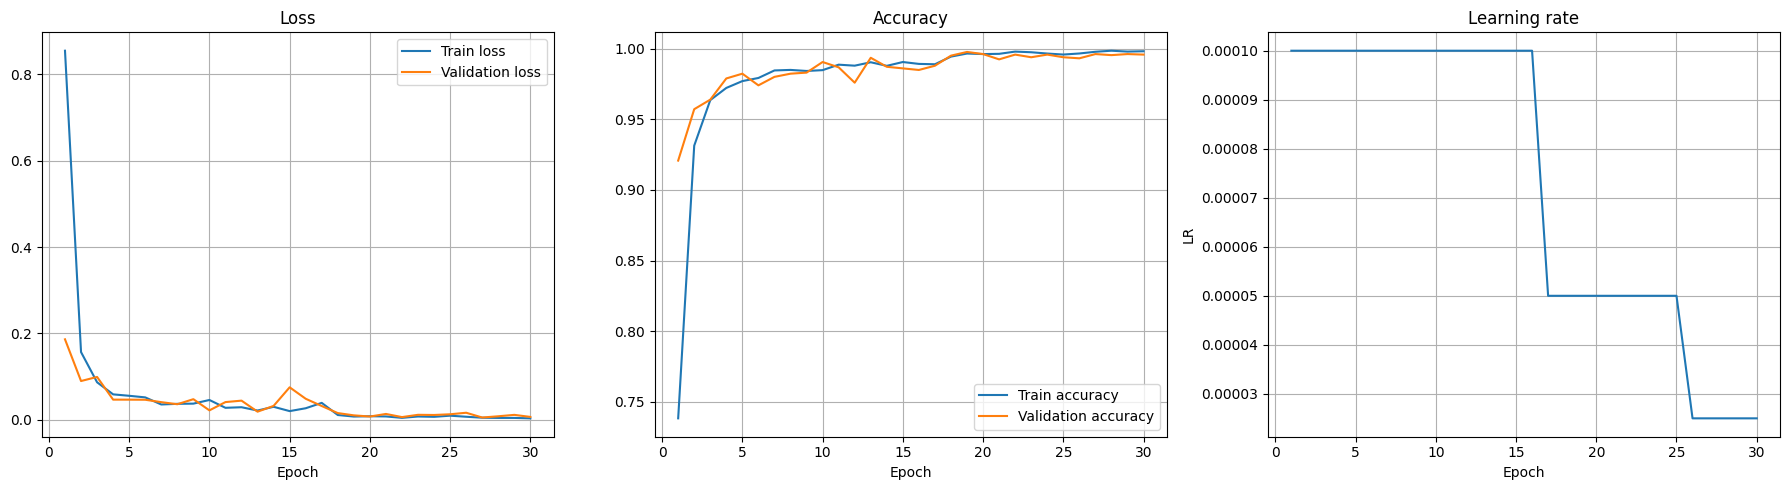

In [70]:
import matplotlib.pyplot as plt
epoch_numbers = range(
    1,
    len(history["train_loss"]) + 1
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

axes[0].plot(
    epoch_numbers,
    history["train_loss"],
    label="Train loss"
)

axes[0].plot(
    epoch_numbers,
    history["val_loss"],
    label="Validation loss"
)

axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    epoch_numbers,
    history["train_accuracy"],
    label="Train accuracy"
)

axes[1].plot(
    epoch_numbers,
    history["val_accuracy"],
    label="Validation accuracy"
)

axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

axes[2].plot(
    epoch_numbers,
    history["learning_rate"]
)

axes[2].set_title("Learning rate")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("LR")
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [73]:
import pandas as pd
from sklearn.metrics import classification_report

classes = [
    "Speed limit (20km/h)",                         # 0
    "Speed limit (30km/h)",                         # 1
    "Speed limit (50km/h)",                         # 2
    "Speed limit (60km/h)",                         # 3
    "Speed limit (70km/h)",                         # 4
    "Speed limit (80km/h)",                         # 5
    "End of speed limit (80km/h)",                  # 6
    "Speed limit (100km/h)",                        # 7
    "Speed limit (120km/h)",                        # 8
    "No passing",                                   # 9
    "No passing for vehicles over 3.5 tons",        # 10
    "Right-of-way at the next intersection",        # 11
    "Priority road",                                # 12
    "Yield",                                        # 13
    "Stop",                                         # 14
    "No vehicles",                                  # 15
    "Vehicles over 3.5 tons prohibited",            # 16
    "No entry",                                     # 17
    "General caution",                              # 18
    "Dangerous curve to the left",                  # 19
    "Dangerous curve to the right",                 # 20
    "Double curve",                                 # 21
    "Bumpy road",                                   # 22
    "Slippery road",                                # 23
    "Road narrows on the right",                    # 24
    "Road work",                                    # 25
    "Traffic signals",                              # 26
    "Pedestrians",                                  # 27
    "Children crossing",                            # 28
    "Bicycles crossing",                            # 29
    "Beware of ice/snow",                           # 30
    "Wild animals crossing",                        # 31
    "End of all speed and passing limits",          # 32
    "Turn right ahead",                             # 33
    "Turn left ahead",                              # 34
    "Ahead only",                                   # 35
    "Go straight or right",                         # 36
    "Go straight or left",                          # 37
    "Keep right",                                   # 38
    "Keep left",                                    # 39
    "Roundabout mandatory",                         # 40
    "End of no passing",                            # 41
    "End of no passing for vehicles over 3.5 tons"  # 42
]

report = classification_report(
    all_labels,
    all_predictions,
    target_names=classes,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

report_df.to_csv(
    "GTSRB_fine_tunning_RESNET18_test_classification_report.csv",
    index=True
)

history_df = pd.DataFrame(history)

history_df.index = history_df.index + 1
history_df.index.name = "epoch"

history_df.to_csv(
    "GTSRB_fine_tunning_RESNET18_history.csv"
)

history_df.head()

,train_loss,val_loss,train_accuracy,val_accuracy,learning_rate
epoch,,,,,
1,0.855030,0.186086,0.738238,0.920796,0.0001
2,0.156494,0.089373,0.931390,0.957207,0.0001
3,0.086487,0.098857,0.963630,0.963964,0.0001
4,0.058458,0.046251,0.972264,0.978979,0.0001
5,0.055166,0.046192,0.977102,0.982357,0.0001
